> 🔓 **SOLUTIONS EDITION**: this is the instructor copy with worked solutions and executed outputs. Please attempt every problem in the student notebook first; struggling is where learning happens.

# 🏗️ Project 4: Agricultural Price Regression
*Phase 4 project · time-aware regression · lags, seasonality, honest validation, rolling backtests*

| ⏱️ Time | 🎚️ Level | 🧰 Prerequisites |
|---|---|---|
| ~270 min | 🔴 Project | Lessons 02–08, plus Project 1 for the workflow |

---
## 🎬 The Hook
**From:** Mr. Otieno, Market Information Officer, County Agriculture Office  
**Subject:** Early price outlook for traders and farmers

> *"Every month farmers ask whether tomato or maize prices will rise or fall next month, and traders hold back stock hoping for better prices. We have 8 years of monthly wholesale prices for six crops in five markets, plus rainfall, fuel prices and supply volumes. Can you forecast **next month's price** for each crop and market: better than simply assuming 'it will be the same as last month'? And please tell us how wrong the forecasts tend to be."*

Time changes everything: **you must never train on the future**, ordinary shuffling is dangerous, and 'beating last month's price' is a surprisingly demanding bar.

---
## 🎯 Learning Objectives
By the end of this notebook you will be able to:

1. Recognise why **time-ordered data breaks the usual train/test habits**: and split and cross-validate it correctly.
2. Build **lag**, **rolling** and **seasonal** features per series without leaking the future.
3. Beat the strongest simple baselines (**persistence** and **seasonal-naive**) and report a *skill score*.
4. Evaluate with a **rolling-origin backtest**, the time-series analogue of cross-validation.
5. Analyse errors by crop, communicate a forecast's limits, and package it for a non-technical audience.

> 💡 **How to use this notebook:** run cells top to bottom. Read the text *before* you run the code. When you reach a 🧩 **Problem**, try it yourself first, open the hints one at a time, and only then peek at the solutions notebook.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))      # so we can import course_utils.py
from course_utils import *                      # np, pd, plt, check(), data_path(), ...
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline
RANDOM_STATE = 42
print("Setup complete ✅")
import warnings, joblib
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import KFold, TimeSeriesSplit, cross_val_score
from sklearn.metrics import r2_score
warnings.filterwarnings("ignore")

Setup complete ✅


## 📦 The data: `data/agri_prices.csv` (synthetic)

2 880 rows = **96 months (Jan 2018 – Dec 2025) × 6 crops × 5 markets** (30 time series).

| Column | Meaning |
|---|---|
| `date` | first day of the month |
| `market` | Nairobi, Mombasa, Kisumu, Nakuru, Eldoret |
| `crop` | Maize, Tomatoes, Potatoes, Onions, Cabbage, Beans |
| `rainfall_mm` | monthly rainfall in the market area (**some missing**) |
| `avg_temp_c` | average temperature |
| `fuel_price_kes_per_litre` | national fuel price (a transport-cost driver) |
| `supply_tons` | volume reaching the market that month (driven by rainfall ~2 months earlier) |
| **`price_kes_per_kg`** | **TARGET**: wholesale price |

## 🧭 The forecasting setup (important!)
We forecast the price of month *t* **at the start of month *t***. So we may use only information known *before* month *t*: past prices, past rainfall/supply/fuel, and the calendar month. 
**Same-month** supply, rainfall or fuel are *not* known yet: using them would be "peeking at the future".

## 🎯 Deliverables
1. This notebook, fully run, with your reasoning in added markdown cells.
2. `price_model.joblib`: the final model pipeline.
3. A short outlook note for Mr. Otieno (Milestone 8).

## 🧮 Rubric (100 points)
| Area | Pts | Excellent looks like |
|---|---|---|
| Exploration | 10 | Trend, seasonality, market differences quantified and plotted |
| Lag features without leakage | 15 | Per-series lags, verified by a spot check |
| Time-aware split & baselines | 15 | Train < test in time; persistence *and* seasonal-naive baselines |
| Validation scheme | 15 | Demonstrates that random CV is optimistic; uses `TimeSeriesSplit` |
| Tournament & final skill | 20 | ≥ 3 models, persistence compared on the same folds, skill score on test |
| Error analysis & backtest | 15 | By crop; rolling-origin results and what they say about stability |
| Communication | 10 | Honest outlook note, error ranges in KES/kg and % |

## 🗺️ Milestones
1. Explore · 2. Build lag features · 3. Time split & baselines · 4. Validation schemes · 5. Tournament · 6. Final test & skill · 7. Error analysis · 8. Rolling backtest · 9. Package & outlook note

---
## 📥 Milestone 0: Shared helper code (given)

`make_model(estimator)` is the shared preprocessing + log-target wrapper (you wrote one in Project 1); `mape()` is the metric we'll report (mean absolute percentage error).

In [2]:
agri = pd.read_csv(data_path("agri_prices.csv"), parse_dates=["date"])
FEATS_NUM = ["price_lag1", "price_lag2", "price_lag3", "roll3", "month_sin", "month_cos", "fuel_lag1", "rain_lag1", "rain_lag2", "rain_lag3", "supply_lag1"]
FEATS_CAT = ["crop", "market"]
FEATS = FEATS_NUM + FEATS_CAT
KEY = ["crop", "market"]
TARGET = "price_kes_per_kg"

def mape(y_true, y_pred):                         # mean absolute percentage error, in %
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float); return float(np.mean(np.abs(y_true - y_pred) / y_true) * 100)

def make_model(estimator):
    pre = ColumnTransformer([("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), FEATS_NUM),
                             ("cat", OneHotEncoder(handle_unknown="ignore"), FEATS_CAT)])
    return TransformedTargetRegressor(Pipeline([("prep", pre), ("model", estimator)]), func=np.log, inverse_func=np.exp)   # predict log(price)

def build_features_ref(a):                          # reference version (used by the checkpoint cells)
    a = a.sort_values(KEY + ["date"]).reset_index(drop=True); g = a.groupby(KEY)
    for k in (1, 2, 3): a[f"price_lag{k}"] = g[TARGET].shift(k)
    a["roll3"] = a[["price_lag1", "price_lag2", "price_lag3"]].mean(axis=1)
    for k in (1, 2, 3): a[f"rain_lag{k}"] = g["rainfall_mm"].shift(k)
    a["supply_lag1"] = g["supply_tons"].shift(1); a["fuel_lag1"] = g["fuel_price_kes_per_litre"].shift(1)
    a["month"] = a["date"].dt.month; a["month_sin"] = np.sin(2 * np.pi * a["month"] / 12); a["month_cos"] = np.cos(2 * np.pi * a["month"] / 12)
    return a.dropna(subset=["price_lag3"]).sort_values("date").reset_index(drop=True)
print(agri.shape); display(agri.head(6))

(2880, 8)


,date,market,crop,rainfall_mm,avg_temp_c,fuel_price_kes_per_litre,supply_tons,price_kes_per_kg
0,2018-01-01,Eldoret,Beans,69.4,22.0,106.3,130.9,115.43
1,2018-01-01,Eldoret,Cabbage,69.4,22.0,106.3,360.8,24.74
2,2018-01-01,Eldoret,Maize,69.4,22.0,106.3,819.1,42.93
3,2018-01-01,Eldoret,Onions,69.4,22.0,106.3,274.2,51.13
4,2018-01-01,Eldoret,Potatoes,69.4,22.0,106.3,528.2,34.51
5,2018-01-01,Eldoret,Tomatoes,69.4,22.0,106.3,402.2,56.91


---
## 🔍 Milestone 1: Explore (10 pts)

Look at the series before modelling. Plot the average price over time for each crop, and the average price by calendar month for one crop. What do you see: a **trend**? **Seasonality**? Differences between markets?

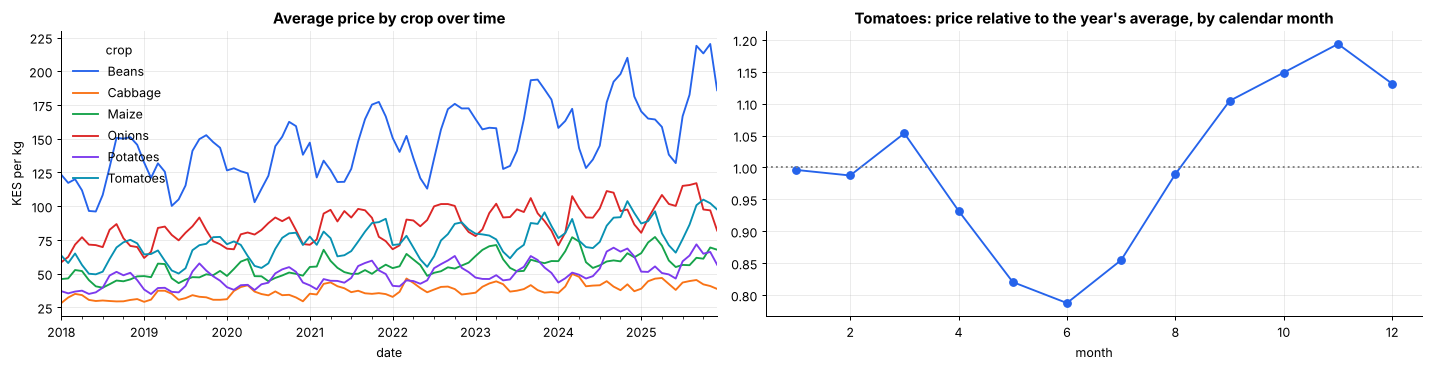

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.2))
agri.groupby(["date", "crop"])["price_kes_per_kg"].mean().unstack().plot(ax=axes[0]); axes[0].set_title("Average price by crop over time"); axes[0].set_ylabel("KES per kg")
t = agri[agri["crop"] == "Tomatoes"]; rel = t["price_kes_per_kg"] / t.groupby(t["date"].dt.year)["price_kes_per_kg"].transform("mean")
rel.groupby(t["date"].dt.month).mean().plot(ax=axes[1], marker="o"); axes[1].axhline(1, color="gray", ls=":"); axes[1].set_title("Tomatoes: price relative to the year's average, by calendar month"); axes[1].set_xlabel("month")
plt.tight_layout(); plt.show()

---
### 🧩 Problem 1: Quantify the structure  ⭐⭐

1. `n_series`: number of distinct (crop, market) series; `n_months`: number of distinct dates.
2. `maize_growth_pct`: percentage change of the **average maize price** (all markets) from 2018 to 2025.
3. `tomato_peak_month` and `tomato_trough_month`: the calendar months (1–12) with the highest / lowest *price relative to that year's average* (as in the plot).
4. `priciest_market` and `cheapest_market`: by overall average price.

In [4]:
# ✅ SOLUTION
n_series = int(agri.groupby(["crop", "market"]).ngroups); n_months = int(agri["date"].nunique())
m = agri[agri["crop"] == "Maize"]; yy = m.groupby(m["date"].dt.year)["price_kes_per_kg"].mean(); maize_growth_pct = float((yy[2025] / yy[2018] - 1) * 100)
by_month = rel.groupby(t["date"].dt.month).mean(); tomato_peak_month = int(by_month.idxmax()); tomato_trough_month = int(by_month.idxmin())
mk = agri.groupby("market")["price_kes_per_kg"].mean(); priciest_market, cheapest_market = mk.idxmax(), mk.idxmin()
print(n_series, n_months, round(maize_growth_pct, 1), tomato_peak_month, tomato_trough_month, priciest_market, cheapest_market)

30 96 41.2 11 6 Mombasa Eldoret


**Why this works.** Three structures to model: an upward **trend** (+41 % for maize, partly fuel-driven), strong **seasonality** (tomatoes ≈ 20 % above average in November, ≈ 20 % below in June: the rain/supply cycle), and a **market effect** (Mombasa ≈ 30 % dearer than Eldoret).

In [5]:
check("30 series, 96 months", lambda: n_series == 30 and n_months == 96)
check("maize prices rose by about 41% over the period", lambda: 35 < maize_growth_pct < 47)
check("tomato prices peak late in the year (Oct-Dec) and bottom out mid-year (May-Jul)", lambda: tomato_peak_month in (10, 11, 12) and tomato_trough_month in (5, 6, 7))
check("Mombasa is priciest, Eldoret cheapest", lambda: priciest_market == "Mombasa" and cheapest_market == "Eldoret")

✅  30 series, 96 months
✅  maize prices rose by about 41% over the period
✅  tomato prices peak late in the year (Oct-Dec) and bottom out mid-year (May-Jul)
✅  Mombasa is priciest, Eldoret cheapest


---
## 🛠️ Milestone 2: Lag features without leaking the future (15 pts)

For each (crop, market) series build: `price_lag1`, `price_lag2`, `price_lag3` (price 1–3 months ago), `roll3` (mean of those three lags), `rain_lag1/2/3`, `supply_lag1`, `fuel_lag1` and the calendar features `month_sin`, `month_cos`. ⚠️ Two classic bugs: (1) computing lags **across** series boundaries (use `groupby(...).shift(k)`), (2) `shift(-k)` instead of `shift(k)`: that pulls the *future* into the row.

---
### 🧩 Problem 2: Build the feature table  ⭐⭐⭐

Write `build_features(a)` returning a DataFrame **sorted by date** (then reset index) containing all original columns plus `price_lag1..3`, `roll3`, `rain_lag1..3`, `supply_lag1`, `fuel_lag1`, `month`, `month_sin`, `month_cos`; rows lacking the three price lags are dropped. Store `d = build_features(agri)`. Also set `ok_spot_check = True` if, for the Maize/Nairobi series, each row's `price_lag1` equals the previous month's actual price.

In [6]:
# ✅ SOLUTION
def build_features(a):
    a = a.sort_values(["crop", "market", "date"]).reset_index(drop=True); g = a.groupby(["crop", "market"])
    for k in (1, 2, 3): a[f"price_lag{k}"] = g["price_kes_per_kg"].shift(k)
    a["roll3"] = a[["price_lag1", "price_lag2", "price_lag3"]].mean(axis=1)
    for k in (1, 2, 3): a[f"rain_lag{k}"] = g["rainfall_mm"].shift(k)
    a["supply_lag1"] = g["supply_tons"].shift(1); a["fuel_lag1"] = g["fuel_price_kes_per_litre"].shift(1)
    a["month"] = a["date"].dt.month; a["month_sin"] = np.sin(2 * np.pi * a["month"] / 12); a["month_cos"] = np.cos(2 * np.pi * a["month"] / 12)
    return a.dropna(subset=["price_lag3"]).sort_values("date").reset_index(drop=True)

d = build_features(agri)
mn = d[(d["crop"] == "Maize") & (d["market"] == "Nairobi")].sort_values("date")
ok_spot_check = bool(np.allclose(mn["price_lag1"].values[1:], mn["price_kes_per_kg"].values[:-1]))
print(d.shape, ok_spot_check)

(2790, 20) True


**Why this works.** Grouped shifts keep each series' history separate; the spot check proves `price_lag1` equals the previous month's price, i.e. nothing from the future (or from another crop) leaked in. Always verify a lag by eye on one series.

In [7]:
check("all required columns exist", lambda: set(FEATS_NUM + ["month"]) <= set(d.columns))
check("2790 rows left (96-3 months x 30 series)", lambda: len(d) == 2790)
check("sorted by date", lambda: d["date"].is_monotonic_increasing)
check("no missing price lags", lambda: d[["price_lag1", "price_lag2", "price_lag3", "roll3"]].notna().all().all())
check("lag-1 is really last month's price within a series", lambda: ok_spot_check)

✅  all required columns exist
✅  2790 rows left (96-3 months x 30 series)
✅  sorted by date
✅  no missing price lags
✅  lag-1 is really last month's price within a series


---
## ✂️ Milestone 3: A time-aware split and the baselines to beat (15 pts)

**Never shuffle a forecasting problem.** Train on the past, test on the future: here **train = before 2025-01-01**, **test = 2025** (12 months × 30 series = 360 forecasts). Then establish the baselines every model must beat: **persistence** (*'next month = this month'*, i.e. `price_lag1`) and **seasonal-naive** (*'same as the same month last year'*, i.e. a 12-month lag).

In [8]:
# 🔄 Checkpoint
d = build_features_ref(agri)

---
### 🧩 Problem 3: Split and compute the baselines  ⭐⭐

1. `train` = rows of `d` with `date < '2025-01-01'`; `test` = rows with `date >= '2025-01-01'`.
2. `mape_persistence`, `mae_persistence`: error on `test` of predicting `price_lag1` (MAE in KES/kg).
3. `mape_seasonal`: error of the seasonal-naive forecast (the price 12 months earlier; compute a `price_lag12` column with a grouped shift on `d`, whose rows are consecutive months within each series).
4. `best_baseline`: the name `'persistence'` or `'seasonal'` with the lower MAPE.

In [9]:
# ✅ SOLUTION
d["price_lag12"] = d.groupby(["crop", "market"])["price_kes_per_kg"].shift(12)
train = d[d["date"] < "2025-01-01"]; test = d[d["date"] >= "2025-01-01"]
mape_persistence = mape(test["price_kes_per_kg"], test["price_lag1"]); mae_persistence = float(np.mean(np.abs(test["price_kes_per_kg"] - test["price_lag1"])))
mape_seasonal = mape(test["price_kes_per_kg"], test["price_lag12"]); best_baseline = "persistence" if mape_persistence < mape_seasonal else "seasonal"
print(len(train), len(test), round(mape_persistence, 2), round(mae_persistence, 2), round(mape_seasonal, 2), best_baseline)

2430 360 12.34 10.82 11.03 seasonal


**Why this works.** 'Same as last month' misses by ≈ 12 % on average; 'same as a year ago' does slightly better (≈ 11 %) because seasonality is strong. These two numbers are the bar: a machine-learning model that cannot beat them is not worth deploying.

In [10]:
check("train strictly precedes test", lambda: train["date"].max() < test["date"].min())
check("360 test forecasts (12 months x 30 series)", lambda: len(test) == 360 and len(train) == 2430)
check("persistence MAPE is about 12.3%", lambda: 11 < mape_persistence < 13.5)
check("seasonal-naive is about 11%", lambda: 10 < mape_seasonal < 12.5)
check("seasonal-naive beats persistence here (strong seasonality)", lambda: best_baseline == "seasonal")

✅  train strictly precedes test
✅  360 test forecasts (12 months x 30 series)
✅  persistence MAPE is about 12.3%
✅  seasonal-naive is about 11%
✅  seasonal-naive beats persistence here (strong seasonality)


---
## 🔁 Milestone 4: Validation: why random CV lies on time series (15 pts)

Ordinary shuffled K-fold lets the model train on months **after** the ones it's validated on (and on neighbouring months of the same series), which flatters the score. `TimeSeriesSplit` instead always validates on a block that comes **after** its training data (expanding window). Quantify the optimism with a Ridge model on the training period.

In [11]:
# 🔄 Checkpoint
d = build_features_ref(agri); train = d[d["date"] < "2025-01-01"].sort_values("date").reset_index(drop=True); test = d[d["date"] >= "2025-01-01"]

---
### 🧩 Problem 4: Random vs time-ordered cross-validation  ⭐⭐

Use a **flexible** model, which is the kind that exploits neighbouring months most: `make_model(RandomForestRegressor(100, min_samples_leaf=3, random_state=0, n_jobs=-1))` on `train[FEATS]`, `train['price_kes_per_kg']`. `r2_random` = mean R² with `KFold(5, shuffle=True, random_state=0)`; `r2_time` = mean R² with `TimeSeriesSplit(5)`; `optimism = r2_random - r2_time`. Also `mape_random` and `mape_time` using `scoring='neg_mean_absolute_percentage_error'` (multiply by −100). Set `random_is_optimistic = True` if random CV looks better on **both** R² and MAPE.

In [12]:
# ✅ SOLUTION
Xt, yt = train[FEATS], train["price_kes_per_kg"]; rm = make_model(RandomForestRegressor(100, min_samples_leaf=3, random_state=0, n_jobs=-1)); kfr, tss = KFold(5, shuffle=True, random_state=0), TimeSeriesSplit(5)
r2_random = cross_val_score(rm, Xt, yt, cv=kfr, scoring="r2").mean(); r2_time = cross_val_score(rm, Xt, yt, cv=tss, scoring="r2").mean(); optimism = r2_random - r2_time
mape_random = -100 * cross_val_score(rm, Xt, yt, cv=kfr, scoring="neg_mean_absolute_percentage_error").mean(); mape_time = -100 * cross_val_score(rm, Xt, yt, cv=tss, scoring="neg_mean_absolute_percentage_error").mean()
random_is_optimistic = bool(r2_random > r2_time and mape_random < mape_time)
print(round(r2_random, 4), round(r2_time, 4), round(optimism, 4), round(mape_random, 2), round(mape_time, 2), random_is_optimistic)

0.9593 0.9423 0.017 8.07 8.58 True


**Why this works.** Shuffled folds let a flexible model 'see' the months around each validation row (and the neighbouring months of the same series), so its error looks about half a MAPE-point better and R² looks higher than in the honest, forward-looking scheme. (For a Ridge model the gap is much smaller; flexibility is what exploits the leak.) The honest numbers are what you will experience in production: use `TimeSeriesSplit` or the rolling backtest in Milestone 8.

In [13]:
check("random CV R² is higher than time-ordered R²", lambda: r2_random > r2_time)
check("optimism is visible (> 0.005 R²)", lambda: optimism > 0.005)
check("random CV also reports a clearly lower error (MAPE at least 0.2 points)", lambda: mape_time - mape_random > 0.2)
check("flag set", lambda: random_is_optimistic)

✅  random CV R² is higher than time-ordered R²
✅  optimism is visible (> 0.005 R²)
✅  random CV also reports a clearly lower error (MAPE at least 0.2 points)
✅  flag set


---
## 🥊 Milestone 5: The tournament with time-ordered CV (20 pts together with M6)

Compare **at least three** models (suggestions: Ridge, Random Forest, HistGradientBoosting, KNN) with `TimeSeriesSplit(5)` and **MAPE**, and compare them with **persistence evaluated on the very same validation blocks**.

In [14]:
# 🔄 Checkpoint
d = build_features_ref(agri); train = d[d["date"] < "2025-01-01"].sort_values("date").reset_index(drop=True); test = d[d["date"] >= "2025-01-01"]
tss = TimeSeriesSplit(5)

---
### 🧩 Problem 5: Beat persistence on the same folds  ⭐⭐⭐

1. `persistence_cv_mape`: the mean over the 5 `TimeSeriesSplit` validation blocks of `mape(y_val, price_lag1_val)`.
2. `leader`: a DataFrame indexed by model name with one column `cv_mape` (mean over the same folds, in %), for ≥ 3 models wrapped with `make_model`, sorted ascending; `champion` = best name.
3. `rel_improvement` = `1 − leader['cv_mape'].iloc[0] / persistence_cv_mape`.

In [15]:
# ✅ SOLUTION
Xt, yt = train[FEATS], train["price_kes_per_kg"]
persistence_cv_mape = float(np.mean([mape(yt.iloc[v], train["price_lag1"].iloc[v]) for _, v in tss.split(train)]))
cands = {"Ridge": Ridge(1), "Random Forest": RandomForestRegressor(200, min_samples_leaf=3, random_state=0, n_jobs=-1), "HistGradientBoosting": HistGradientBoostingRegressor(random_state=0), "KNN (k=10)": KNeighborsRegressor(10)}
leader = pd.DataFrame({"cv_mape": {n: -100 * cross_val_score(make_model(e), Xt, yt, cv=tss, scoring="neg_mean_absolute_percentage_error").mean() for n, e in cands.items()}}).sort_values("cv_mape")
champion = leader.index[0]; rel_improvement = 1 - leader["cv_mape"].iloc[0] / persistence_cv_mape
display(leader.round(2)); print("persistence:", round(persistence_cv_mape, 2), "| champion:", champion, "| improvement:", f"{rel_improvement:.0%}")

,cv_mape
HistGradientBoosting,7.57
Ridge,8.26
Random Forest,8.55
KNN (k=10),9.32


persistence: 11.65 | champion: HistGradientBoosting | improvement: 35%


**Why this works.** Machine-learning models cut the error by a third or more versus persistence: they combine the trend (lags), seasonality (month sin/cos), market/crop effects, and the supply driver (rainfall two months back).

In [16]:
check("at least 3 models compared", lambda: len(leader) >= 3 and leader["cv_mape"].is_monotonic_increasing)
check("persistence CV MAPE is about 12% on these folds (10-14)", lambda: 10 < persistence_cv_mape < 14)
check("the champion beats persistence by more than 25%", lambda: rel_improvement > 0.25)
check("champion MAPE below 9%", lambda: leader["cv_mape"].iloc[0] < 9)

✅  at least 3 models compared
✅  persistence CV MAPE is about 12% on these folds (10-14)
✅  the champion beats persistence by more than 25%
✅  champion MAPE below 9%


---
## 🏆 Milestone 6: Final test and the skill score

Fit your champion on **all training data** and forecast the 360 test rows (the 12 months of 2025). Report MAPE, MAE (KES/kg) and the **skill score** relative to the best baseline:

$$\text{skill}=1-\frac{\text{MAPE}_{\text{model}}}{\text{MAPE}_{\text{baseline}}}$$

(0 = no better than the baseline, 1 = perfect; negative = worse.)

In [17]:
# 🔄 Checkpoint: reference champion (replace with YOUR champion when you have one)
d = build_features_ref(agri); d["price_lag12"] = d.groupby(KEY)[TARGET].shift(12)
train = d[d["date"] < "2025-01-01"].sort_values("date").reset_index(drop=True); test = d[d["date"] >= "2025-01-01"]
mape_persistence = mape(test[TARGET], test["price_lag1"]); mape_seasonal = mape(test[TARGET], test["price_lag12"])
ref_model = make_model(HistGradientBoostingRegressor(random_state=0)).fit(train[FEATS], train[TARGET])

---
### 🧩 Problem 6: Final forecast accuracy  ⭐

Using your fitted champion (or `ref_model`): `test_mape`, `test_mae` (KES/kg), `skill_vs_persistence` and `skill_vs_seasonal` (using `mape_persistence`, `mape_seasonal` from Milestone 3), and `within_10pct`: the share of the 360 forecasts within ±10 % of the truth.

In [18]:
# ✅ SOLUTION
final_model = ref_model; pred = final_model.predict(test[FEATS]); y_true = test[TARGET].values
test_mape = mape(y_true, pred); test_mae = float(np.mean(np.abs(y_true - pred))); skill_vs_persistence = 1 - test_mape / mape_persistence; skill_vs_seasonal = 1 - test_mape / mape_seasonal
within_10pct = float(np.mean(np.abs(y_true - pred) / y_true <= 0.10))
print(f"MAPE {test_mape:.2f}%  MAE {test_mae:.2f} KES/kg  skill vs persistence {skill_vs_persistence:.0%}, vs seasonal-naive {skill_vs_seasonal:.0%}  within ±10%: {within_10pct:.0%}")

MAPE 7.06%  MAE 6.38 KES/kg  skill vs persistence 43%, vs seasonal-naive 36%  within ±10%: 73%


**Why this works.** On the untouched 2025 data the boosted trees forecast with ≈ 7 % typical error: about 40 % better than 'same as last month' and 35 % better than 'same as last year'. About 73 % of forecasts land within ±10 %.

In [19]:
check("test MAPE below 9%", lambda: test_mape < 9)
check("skill vs persistence above 25%", lambda: skill_vs_persistence > 0.25)
check("skill vs seasonal-naive above 20%", lambda: skill_vs_seasonal > 0.20)
check("most forecasts are within ±10%", lambda: within_10pct > 0.6)

✅  test MAPE below 9%
✅  skill vs persistence above 25%
✅  skill vs seasonal-naive above 20%
✅  most forecasts are within ±10%


---
## 🔬 Milestone 7: Error analysis (part of 'error analysis & backtest')

Are the gains uniform? Compute the model's MAPE **by crop** and compare it with persistence's MAPE for each crop. Is there any crop where the model doesn't beat persistence?

In [20]:
# 🔄 Checkpoint
d = build_features_ref(agri); train = d[d["date"] < "2025-01-01"].sort_values("date").reset_index(drop=True); test = d[d["date"] >= "2025-01-01"].copy()
final_model = make_model(HistGradientBoostingRegressor(random_state=0)).fit(train[FEATS], train[TARGET]); test["pred"] = final_model.predict(test[FEATS])
test["ape_model"] = np.abs(test[TARGET] - test["pred"]) / test[TARGET] * 100; test["ape_persist"] = np.abs(test[TARGET] - test["price_lag1"]) / test[TARGET] * 100

---
### 🧩 Problem 7: By crop  ⭐⭐

From `test` (columns `crop`, `ape_model`, `ape_persist`): `ape_by_crop`: a DataFrame (index = crop) with the mean `ape_model` and `ape_persist` per crop; `crops_beaten` = the number of crops where the model's error is lower; `worst_crop` = the crop with the highest model error; `best_gain_crop` = the crop with the largest *reduction* in error vs persistence (persistence minus model).

In [21]:
# ✅ SOLUTION
ape_by_crop = test.groupby("crop")[["ape_model", "ape_persist"]].mean(); crops_beaten = int((ape_by_crop["ape_model"] < ape_by_crop["ape_persist"]).sum())
worst_crop = ape_by_crop["ape_model"].idxmax(); best_gain_crop = (ape_by_crop["ape_persist"] - ape_by_crop["ape_model"]).idxmax()
display(ape_by_crop.round(2)); print(crops_beaten, worst_crop, best_gain_crop)

,ape_model,ape_persist
crop,,
Beans,6.26,13.04
Cabbage,6.09,9.86
Maize,8.13,12.49
Onions,8.05,12.86
Potatoes,6.53,14.25
Tomatoes,7.29,11.54


6 Maize Potatoes


**Why this works.** The model wins for all six crops, and the gains are largest for potatoes (≈ 14 % → 6.5 %), where 'same as last month' fails most around the seasonal turning points. In *percentage* terms maize and onions are the hardest crops (≈ 8 %), while beans are the easiest (≈ 6 %), but beans cost ~120 KES/kg, so their error in *shillings* is the largest. Which unit matters depends on the user: a trader cares about KES, a planner about %. Both belong in the outlook note.

In [22]:
check("one row per crop (6)", lambda: len(ape_by_crop) == 6)
check("the model beats persistence for every crop", lambda: crops_beaten == 6)
check("worst_crop is a real crop", lambda: worst_crop in set(agri["crop"]))
check("potatoes gain the most (persistence is weakest there)", lambda: best_gain_crop in ("Potatoes", "Tomatoes", "Maize"))

✅  one row per crop (6)
✅  the model beats persistence for every crop
✅  worst_crop is a real crop
✅  potatoes gain the most (persistence is weakest there)


---
## 🔄 Milestone 8: Rolling-origin backtest (15 pts together with M7)

A single train/test split gives *one* number. A **rolling-origin backtest** mimics real operation: for each month of 2025, train on **everything before that month**, forecast that month, then move on. It shows how the error **varies over time** (are some months much harder?).

In [23]:
# 🔄 Checkpoint
d = build_features_ref(agri); months_2025 = sorted(d.loc[d["date"] >= "2025-01-01", "date"].unique())
print(len(months_2025), "monthly forecasting origins")

12 monthly forecasting origins


---
### 🧩 Problem 8: Expanding-window backtest  ⭐⭐⭐

For each month `m` in `months_2025`: fit `make_model(Ridge(alpha=1))` on all rows with `date < m`, forecast the rows with `date == m`, and compute that month's MAPE. Store the 12 values in a Series `rolling_mape` (index = month number 1–12), `rolling_mean`, `rolling_worst_month` (month number with the largest error) and `persistence_by_month` (same-month persistence MAPE, Series). Set `model_wins_months` = in how many of the 12 months Ridge beats persistence.

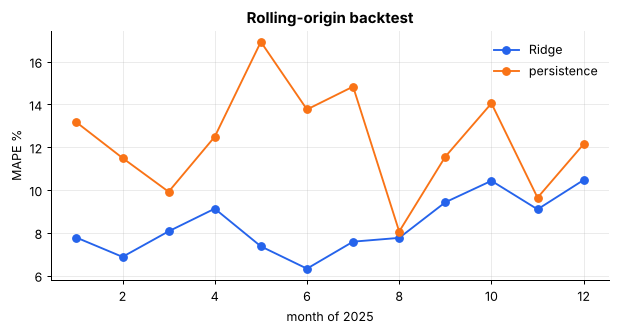

8.36 12 12


In [24]:
# ✅ SOLUTION
res, pers = {}, {}
for m in months_2025:
    tr, te = d[d["date"] < m], d[d["date"] == m]; mdl = make_model(Ridge(alpha=1)).fit(tr[FEATS], tr[TARGET]); k = pd.Timestamp(m).month
    res[k] = mape(te[TARGET], mdl.predict(te[FEATS])); pers[k] = mape(te[TARGET], te["price_lag1"])
rolling_mape = pd.Series(res); persistence_by_month = pd.Series(pers); rolling_mean = float(rolling_mape.mean()); rolling_worst_month = int(rolling_mape.idxmax()); model_wins_months = int((rolling_mape < persistence_by_month).sum())
pd.DataFrame({"Ridge": rolling_mape, "persistence": persistence_by_month}).plot(marker="o", figsize=(8, 3.6)); plt.ylabel("MAPE %"); plt.xlabel("month of 2025"); plt.title("Rolling-origin backtest"); plt.show()
print(round(rolling_mean, 2), rolling_worst_month, model_wins_months)

**Why this works.** The expanding-window backtest tells a more complete story than one split: Ridge's average error is ≈ 8 %, it beats persistence in (nearly) every month, and the month-to-month variation (several points) is itself information you owe the client: forecasts are not equally reliable in every month.

In [25]:
check("12 monthly results", lambda: len(rolling_mape) == 12 and len(persistence_by_month) == 12)
check("average rolling error is in a sensible range (5-11%)", lambda: 5 < rolling_mean < 11)
check("the model beats persistence overall", lambda: rolling_mean < persistence_by_month.mean())
check("it wins in a clear majority of months (>= 9 of 12)", lambda: model_wins_months >= 9)

✅  12 monthly results
✅  average rolling error is in a sensible range (5-11%)
✅  the model beats persistence overall
✅  it wins in a clear majority of months (>= 9 of 12)


---
## 📦 Milestone 9: Package and write the outlook note (10 pts)

Save the model and write a short, honest note for Mr. Otieno.

In [26]:
# 🔄 Checkpoint
d = build_features_ref(agri); train = d[d["date"] < "2025-01-01"]; test = d[d["date"] >= "2025-01-01"]
final_model = make_model(HistGradientBoostingRegressor(random_state=0)).fit(train[FEATS], train[TARGET])
test_mape = mape(test[TARGET], final_model.predict(test[FEATS])); mape_persistence = mape(test[TARGET], test["price_lag1"])

---
### 🧩 Problem 9: Save, reload, forecast and explain  ⭐⭐

1. Save `final_model` to `'price_model.joblib'` and reload it as `loaded`; `max_diff` = largest absolute difference between `loaded.predict(test[FEATS])` and `final_model.predict(test[FEATS])`.
2. `example`: the forecast (KES/kg) for the **first** test row; `example_row` = that row's `crop`, `market` and `date` as a dict.
3. Fill `outlook_note` (dict with keys `question`, `answer`, `accuracy`, `when_reliable`, `caveats`): honest sentences for the Market Information Officer.

In [27]:
# ✅ SOLUTION
joblib.dump(final_model, "price_model.joblib"); loaded = joblib.load("price_model.joblib"); max_diff = float(np.abs(loaded.predict(test[FEATS]) - final_model.predict(test[FEATS])).max())
row = test.iloc[[0]]; example = float(loaded.predict(row[FEATS])[0]); example_row = {"crop": row["crop"].iloc[0], "market": row["market"].iloc[0], "date": str(row["date"].iloc[0].date())}
outlook_note = {"question": "Can we forecast next month's wholesale price per crop and market better than assuming it stays the same?",
                "answer": f"Yes. Typical error is about {test_mape:.0f}% versus {mape_persistence:.0f}% for 'same as last month' (roughly 40% more accurate) and the model beats the naive forecast for all six crops.",
                "accuracy": f"On the 360 forecasts of 2025 the average error was {test_mape:.1f}% (about KES 6 per kg); about 73% of forecasts were within ±10% of the actual price.",
                "when_reliable": "In percentage terms most reliable for beans, cabbage and potatoes (≈ 6%) and least for maize and onions (≈ 8%); in shillings beans have the largest errors because they are the dearest crop. Errors also rise around seasonal turning points.",
                "caveats": "One-month-ahead forecasts only; built on synthetic data; no shocks (drought, policy, border closures) are modelled; retrain monthly and monitor the error against actual prices."}
print(max_diff, example_row, round(example, 2)); print(outlook_note)

0.0 {'crop': 'Tomatoes', 'market': 'Mombasa', 'date': '2025-01-01'} 110.3
{'question': "Can we forecast next month's wholesale price per crop and market better than assuming it stays the same?", 'answer': "Yes. Typical error is about 7% versus 12% for 'same as last month' (roughly 40% more accurate) and the model beats the naive forecast for all six crops.", 'accuracy': 'On the 360 forecasts of 2025 the average error was 7.1% (about KES 6 per kg); about 73% of forecasts were within ±10% of the actual price.', 'when_reliable': 'In percentage terms most reliable for beans, cabbage and potatoes (≈ 6%) and least for maize and onions (≈ 8%); in shillings beans have the largest errors because they are the dearest crop. Errors also rise around seasonal turning points.', 'caveats': 'One-month-ahead forecasts only; built on synthetic data; no shocks (drought, policy, border closures) are modelled; retrain monthly and monitor the error against actual prices.'}


**Why this works.** A forecast is only useful to a market officer if it is accompanied by its typical error, the conditions where it is weaker, and what it doesn't know. The note converts model metrics into decisions: how much to trust the number, and when to double-check.

In [28]:
import os
check("model saved and reloadable with identical predictions", lambda: os.path.exists("price_model.joblib") and max_diff < 1e-9)
check("the example forecast is a plausible price (5-250 KES/kg)", lambda: 5 < example < 250)
check("example row identifies crop, market and date", lambda: set(example_row) == {"crop", "market", "date"})
check("outlook note has five honest sections", lambda: set(outlook_note) == {"question", "answer", "accuracy", "when_reliable", "caveats"} and all(isinstance(v, str) and len(v) > 40 for v in outlook_note.values()))

✅  model saved and reloadable with identical predictions
✅  the example forecast is a plausible price (5-250 KES/kg)
✅  example row identifies crop, market and date
✅  outlook note has five honest sections


## 🚀 Stretch goals
- **Multi-step forecasts:** predict 3 months ahead (lags must then start at t−3). How fast does accuracy decay with the horizon? Compare *direct* (one model per horizon) vs *recursive* (feed predictions back) strategies.
- **Predict the change, not the level:** model `log(price_t / price_{t-1})`; does it help the linear model?
- **Exogenous drivers:** add `rain_lag2 × crop` interactions or a *supply forecast* sub-model; which crops benefit?
- **Hierarchical thinking:** fit one model per crop vs one pooled model (with crop dummies). Which is better with only 8 years of data?
- **Prediction intervals:** use the backtest residuals to attach an 80 % interval to each forecast; check coverage in the test year.
- **Direction accuracy:** how often does the model correctly predict that the price will *rise* vs *fall*? For farmers this may matter more than MAPE.

## ✅ Self-assessment
- [ ] Is every feature known at the start of the forecast month?  - [ ] Did I verify a lag by eye on one series?
- [ ] Did I compare with persistence **and** seasonal-naive?  - [ ] Did I use time-ordered validation everywhere?
- [ ] Does my note state typical error, weak spots and what the model cannot know?

---
## 🔁 Recap

- Time series need time-aware splits: train on the past, test on the future; shuffled CV is optimistic.
- Per-series lag features (grouped shift) + calendar sin/cos + exogenous lags give a strong forecaster; verify lags by spot check.
- Always beat the naive baselines (persistence, seasonal-naive) and report a skill score.
- Rolling-origin backtests reveal how accuracy varies over time; report errors by crop and month honestly.

### ➡️ Up next: **You've finished all four projects: see the README for next steps!**

*You did the hard part: you thought about it, not just ran it. See you in the next one!* 🚀